# Purged K-Fold with embargo — `quant_forge.validation.PurgedKFold`

This notebook demonstrates and **audits** the splitter on a deterministic synthetic event dataset. It imports the library
implementation; nothing about the splitter is re-implemented here (the only independent logic below is a small
*audit* that re-derives overlaps and embargo positions to check the library's output).

**What this notebook is — and is not.** The data are random numbers with *no* signal. The point is to test
*splitting correctness* (does any training event still share information with the test window? are the embargo
exclusions where the documented convention says?), **not trading alpha**. Scores in the last section are chance-level on
purpose.

**Reference.** M. López de Prado, *Advances in Financial Machine Learning* (2018), chapter 7, §§7.4.1–7.4.3 and
Snippets 7.1–7.3.

| Taken from the book | Implementation choices in QuantForge |
|---|---|
| Observations are *events* with an information interval `[start, end]`; leakage = train/test intervals that share information | Intervals are **closed**: sharing an endpoint counts as overlap (the book's index-based snippet can keep such events) |
| Purge train events overlapping the test window; the window uses the **maximum** test end | Test window = `[earliest test start, max test end]`; purging is applied **independently** of the embargo |
| Embargo as a fraction of the sample, `int(n · pct)`; the position is `searchsorted` of the max test end in the ordered start index (Snippet 7.3) | `side="left"`, `floor(n · pct)` with a float-noise tolerance, clipped at the dataset end; exact boundary behaviour documented in the class docstring |
| Train on observations before *and* after the test fold | Test folds identical in size to `KFold(shuffle=False)`; positional `int` arrays; explicit removal of test indices; `ValueError` on an empty training fold; unsorted / duplicated / grouped / multi-asset input rejected rather than repaired |


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

try:                                   # normal case: `pip install -e .` was run
    import quant_forge
except ModuleNotFoundError:            # fallback: use the repository checkout this notebook lives in
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "quant_forge" / "__init__.py").exists())
    sys.path.insert(0, str(root))
from quant_forge.validation import PurgedKFold

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "hatch.linewidth": 1.0})
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.0.2


## 1. Event table and interval definitions

Every row is one **event** (think: a triple-barrier label or a trade). Two timestamps define it:

* the **index** is the event *start* — when the information used by the features/label begins;
* `event_end` is the event *end* — when the label is resolved (barrier touch / exit time). The information set of the
  event is the **closed interval** `[start, end]`.

Two events *overlap* iff `start_i <= end_j and start_j <= end_i`: containment, partial overlap and **sharing a single endpoint**
all count, and a zero-duration event (`end == start`) is a point. This is what `samples_info_sets` (a `pd.Series`
indexed by start, valued by end) hands to the splitter. End times are *not* sorted: a long early event can end after later ones.

The synthetic data have irregular start times, variable durations (a few are zero) and heavy overlap. Four cases
are **planted** next to fold boundaries so that the edge rules are actually exercised (`K = 5` folds of 12 events):

In [2]:
SEED, N, K = 20261116, 60, 5
rng = np.random.default_rng(SEED)

# irregular start times: 5 min + exponential(40 min) gaps, whole seconds, strictly increasing
gap_s = np.round(60 * (5 + rng.exponential(40, size=N))).astype(int)
start = pd.Timestamp("2024-03-01 09:30:00", tz="UTC") + pd.to_timedelta(np.cumsum(gap_s), unit="s")
# variable durations: log-normal, median ~ 2 h, i.e. several events open at the same time
dur_s = np.round(60 * rng.lognormal(mean=np.log(120), sigma=0.9, size=N)).astype(int)
end = start + pd.to_timedelta(dur_s, unit="s")
end = end.to_series(index=range(N))
start_s = start.to_series(index=range(N))

fold_of = np.repeat(np.arange(K), N // K)
# planted cases ---------------------------------------------------------------------------------
for i in (5, 17, 40):                                  # zero-duration events
    end[i] = start_s[i]
end[11] = start_s[12]                                  # ends exactly where test fold 1 starts (left shared endpoint)
for i in range(24, 36):                                # fold 2: nothing outlives the planted maximum ...
    end[i] = min(end[i], start_s[38] - pd.Timedelta(seconds=1))
end[30] = start_s[38]                                  # ... which equals the start of the TRAIN event 38 (right shared endpoint)
end[8] = end.iloc[12:24].max() + pd.Timedelta(minutes=10)    # long event that contains the whole window of fold 1

info = pd.Series(pd.DatetimeIndex(end), index=pd.DatetimeIndex(start, name="event_start"), name="event_end")

rng2 = np.random.default_rng(SEED + 1)
X = pd.DataFrame({"momentum": np.linspace(0, 3, N) + rng2.normal(size=N),     # drifts, so scaler means differ by fold
                  "volatility": rng2.lognormal(size=N)}, index=info.index)
y = pd.Series(rng2.integers(0, 2, size=N), index=info.index, name="label")    # independent of X: no signal

S_ = info.index.tz_convert(None).to_numpy()
E_ = pd.DatetimeIndex(info).tz_convert(None).to_numpy()
def overlap_matrix(rows, cols):
    # AUDIT helper: closed-interval overlap of every (row, col) pair. Quadratic, fine for 60 events.
    rows, cols = np.asarray(rows), np.asarray(cols)
    return (S_[rows][:, None] <= E_[cols][None, :]) & (S_[cols][None, :] <= E_[rows][:, None])

full = overlap_matrix(np.arange(N), np.arange(N)); np.fill_diagonal(full, False)
events = info.to_frame()
events["duration_min"] = ((pd.DatetimeIndex(info) - info.index) / pd.Timedelta("1min")).round(1)
events["n_overlapping"] = full.sum(1)
events["fold"] = fold_of

assert info.index.is_unique and info.index.is_monotonic_increasing
assert (pd.DatetimeIndex(info) >= info.index).all()
assert not pd.DatetimeIndex(info).is_monotonic_increasing, "end times should NOT be sorted"
print(f"{N} events | {int((events.duration_min == 0).sum())} zero-duration | "
      f"{int((full.sum(1) > 0).sum())} events overlap at least one other | max overlaps per event: {full.sum(1).max()}")
events.head(14)

60 events | 3 zero-duration | 60 events overlap at least one other | max overlaps per event: 24


,event_end,duration_min,n_overlapping,fold
event_start,,,,
2024-03-01 09:45:34+00:00,2024-03-01 10:40:45+00:00,55.2,2,0
2024-03-01 09:57:59+00:00,2024-03-01 11:31:10+00:00,93.2,5,0
2024-03-01 10:15:47+00:00,2024-03-01 11:56:34+00:00,100.8,6,0
2024-03-01 10:56:01+00:00,2024-03-01 13:01:33+00:00,125.5,8,0
2024-03-01 11:17:38+00:00,2024-03-01 18:55:51+00:00,458.2,17,0
2024-03-01 11:30:46+00:00,2024-03-01 11:30:46+00:00,0.0,4,0
2024-03-01 11:45:00+00:00,2024-03-02 01:18:32+00:00,813.5,21,0
2024-03-01 12:27:43+00:00,2024-03-01 14:19:35+00:00,111.9,8,0
2024-03-01 12:38:26+00:00,2024-03-02 03:24:40+00:00,886.2,24,0


In [3]:
planted = pd.DataFrame([
    (5, "zero-duration event (a point)"), (17, "zero-duration event"), (40, "zero-duration event"),
    (11, "ends exactly at the start of event 12 = first event of test fold 1 (train-side shared endpoint)"),
    (30, "test fold 2: its end is the fold's MAXIMUM end and equals the start of train event 38"),
    (8, "long event containing the entire information window of test fold 1"),
], columns=["event", "purpose"]).set_index("event")
assert events.event_end.iloc[11] == events.index[12] and events.event_end.iloc[30] == events.index[38]
planted

,purpose
event,
5,zero-duration event (a point)
17,zero-duration event
40,zero-duration event
11,ends exactly at the start of event 12 = first ...
30,test fold 2: its end is the fold's MAXIMUM end...
8,long event containing the entire information w...


## 2. Ordinary `KFold(shuffle=False)` — the leakage we want to remove

Chronological folds, training on everything outside the test fold. The audit counts **train events whose closed
interval overlaps at least one test event**. For ordinary K-Fold this is not zero — those events carry information
that is also inside the test labels.

In [4]:
def audit(splits, label):
    rows = []
    for f, (tr, te) in enumerate(splits):
        ov = overlap_matrix(tr, te)
        rows.append({"fold": f, "n_test": len(te), "n_train": len(tr),
                     "leaking_train_events": int(ov.any(1).sum()), "leaking_pairs": int(ov.sum())})
    return pd.DataFrame(rows).set_index("fold").rename_axis(label, axis=1)

kfold_splits = list(KFold(K, shuffle=False).split(X))
kfold_audit = audit(kfold_splits, "KFold(shuffle=False)")
assert kfold_audit.leaking_train_events.sum() > 0
kfold_audit

KFold(shuffle=False),n_test,n_train,leaking_train_events,leaking_pairs
fold,,,,
0,12,48,17,46
1,12,48,11,47
2,12,48,9,22
3,12,48,10,29
4,12,48,4,20


## 3. `PurgedKFold`, zero embargo

```python
cv = PurgedKFold(n_splits=5, samples_info_sets=info, pct_embargo=0.0)
```

The test folds are the same as above. For each fold the **test information window** is
`[earliest test start, maximum test end]` — the maximum over the fold, not the end of the last row. Every other event
whose closed interval intersects that window is purged, whether it lies before or after the test fold. With zero
embargo purging still happens.

In [5]:
cv0 = PurgedKFold(n_splits=K, samples_info_sets=info, pct_embargo=0.0)
print(cv0)
details0 = list(cv0.split_with_diagnostics(X))          # same folds as cv0.split(X), plus the reason for each exclusion
splits0 = list(cv0.split(X))
for (tr, te), d in zip(splits0, details0):
    assert np.array_equal(tr, d.train) and np.array_equal(te, d.test)

def fold_table(details, K=K):
    return pd.DataFrame({
        "test_start": [d.test_start.strftime("%m-%d %H:%M") for d in details],
        "max_test_end": [d.test_end.strftime("%m-%d %H:%M") for d in details],
        "n_test": [len(d.test) for d in details], "n_train": [len(d.train) for d in details],
        "n_purged": [len(d.purged) for d in details], "n_embargoed": [len(d.embargoed) for d in details],
    }).rename_axis("fold")
fold_table(details0)

PurgedKFold(n_splits=5, pct_embargo=0.0, samples_info_sets=<60 events, 2024-03-01 09:45:34+00:00 .. 2024-03-03 01:35:20+00:00>)


,test_start,max_test_end,n_test,n_train,n_purged,n_embargoed
fold,,,,,,
0,03-01 09:45,03-02 03:24,12,31,17,0
1,03-01 13:51,03-02 03:14,12,37,11,0
2,03-01 23:44,03-02 10:49,12,39,9,0
3,03-02 09:56,03-02 20:34,12,38,10,0
4,03-02 19:17,03-03 06:02,12,44,4,0


## 4. `PurgedKFold`, positive embargo

```python
cv = PurgedKFold(n_splits=5, samples_info_sets=info, pct_embargo=0.05)   # floor(60 * 0.05) = 3 observations
```

The embargo is a **number of observations**: `floor(n_samples · pct_embargo)` of the *full* input, not a fraction of the
test fold and not a wall-clock duration. Following Snippet 7.3, `p = searchsorted(starts, max_test_end, side="left")`
is the first event starting at or after the test window's end, and positions `p … p + m − 1` (clipped to the
dataset) are excluded from training. Purging stays on; the embargo only *adds* exclusions.

In [6]:
PCT = 0.05
M = int(np.floor(N * PCT)); assert M == 3
cv_e = PurgedKFold(n_splits=K, samples_info_sets=info, pct_embargo=PCT)
details_e = list(cv_e.split_with_diagnostics(X))
fold_table(details_e)

,test_start,max_test_end,n_test,n_train,n_purged,n_embargoed
fold,,,,,,
0,03-01 09:45,03-02 03:24,12,28,17,3
1,03-01 13:51,03-02 03:14,12,34,11,3
2,03-01 23:44,03-02 10:49,12,37,9,2
3,03-02 09:56,03-02 20:34,12,35,10,3
4,03-02 19:17,03-03 06:02,12,44,4,0


## 5. Fold visualisation

One row per fold, one cell per event in chronological order. **Category precedence** (an observation gets exactly one):
`test` > `purged` (closed-interval overlap with the test window) > `embargoed` (inside the embargo window but *not*
already purged or test) > `train`. Colour is backed by hatching (purged `////`, embargoed `xxx`); the exact counts are in the tables.

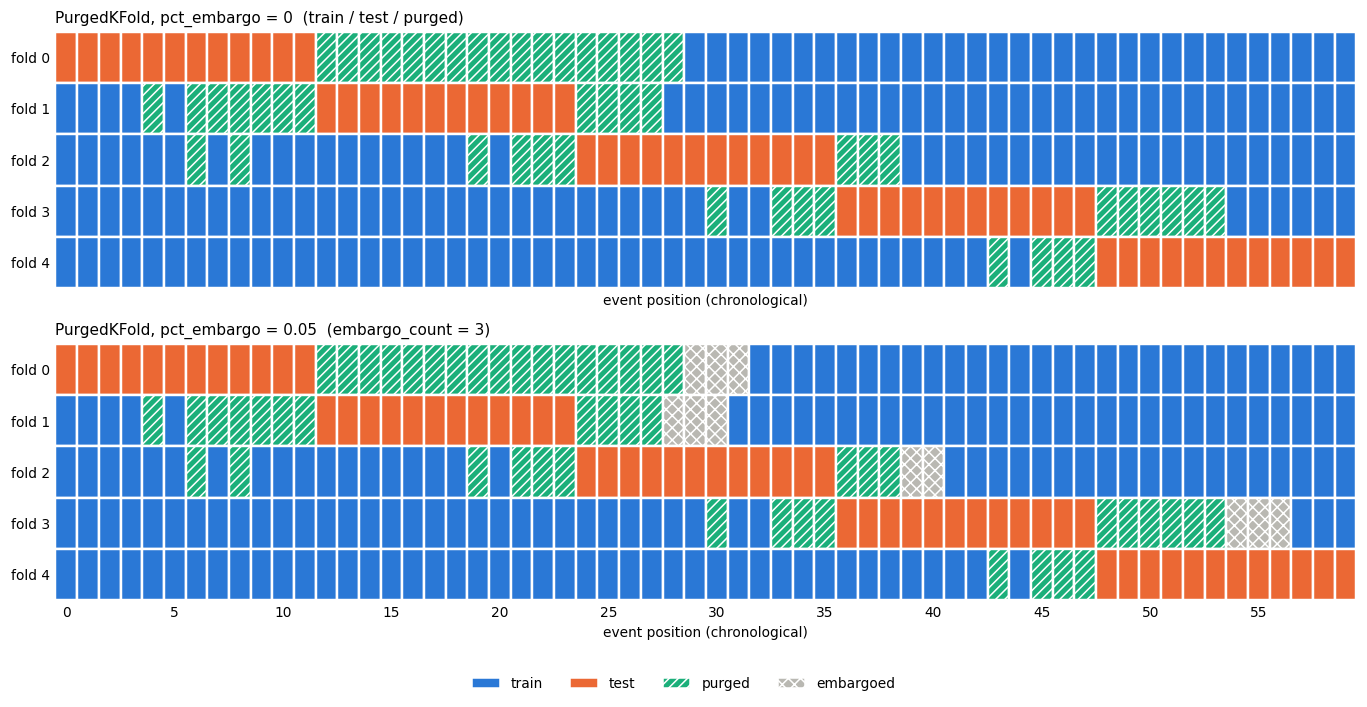

In [7]:
CATS = ["train", "test", "purged", "embargoed"]
COLORS = {"train": "#2a78d6", "test": "#eb6834", "purged": "#1baf7a", "embargoed": "#b9b8b2"}
HATCH = {"train": None, "test": None, "purged": "////", "embargoed": "xxx"}

def category_matrix(details):
    M_ = np.zeros((len(details), N), dtype=int)                    # code = index in CATS
    for f, d in enumerate(details):                                # applied lowest -> highest precedence
        M_[f, d.train] = 0
        M_[f, d.embargoed] = 3
        M_[f, d.purged] = 2
        M_[f, d.test] = 1
    return M_

def plot_cells(ax, details, title):
    cm = category_matrix(details)
    for f in range(cm.shape[0]):
        for i in range(N):
            c = CATS[cm[f, i]]
            ax.add_patch(Rectangle((i, f), 1, 1, facecolor=COLORS[c], edgecolor="white", linewidth=1.6, hatch=HATCH[c]))
    ax.set_xlim(0, N); ax.set_ylim(len(details), 0)
    ax.set_yticks(np.arange(len(details)) + 0.5, [f"fold {f}" for f in range(len(details))])
    ax.set_xticks(np.arange(0, N, 5) + 0.5, np.arange(0, N, 5))
    ax.set_xlabel("event position (chronological)"); ax.set_title(title, loc="left", fontsize=10)
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    return cm

fig, axes = plt.subplots(2, 1, figsize=(12.5, 6.3), sharex=True)
cm0 = plot_cells(axes[0], details0, "PurgedKFold, pct_embargo = 0  (train / test / purged)")
cm_e = plot_cells(axes[1], details_e, f"PurgedKFold, pct_embargo = {PCT}  (embargo_count = {M})")
handles = [Patch(facecolor=COLORS[c], edgecolor="white", hatch=HATCH[c], label=c) for c in CATS]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

**Reading one fold as intervals.** Fold 2 with embargo: each horizontal segment is an event's information interval
(dot = start). The shaded band is the test window `[earliest test start, max test end]`. Event 38 starts *exactly* when
the window ends: it shares an endpoint, so it is purged (closed intervals) and it is also position `p`, the first slot of the
embargo window — the next `M − 1 = 2` events (39, 40) are embargoed.

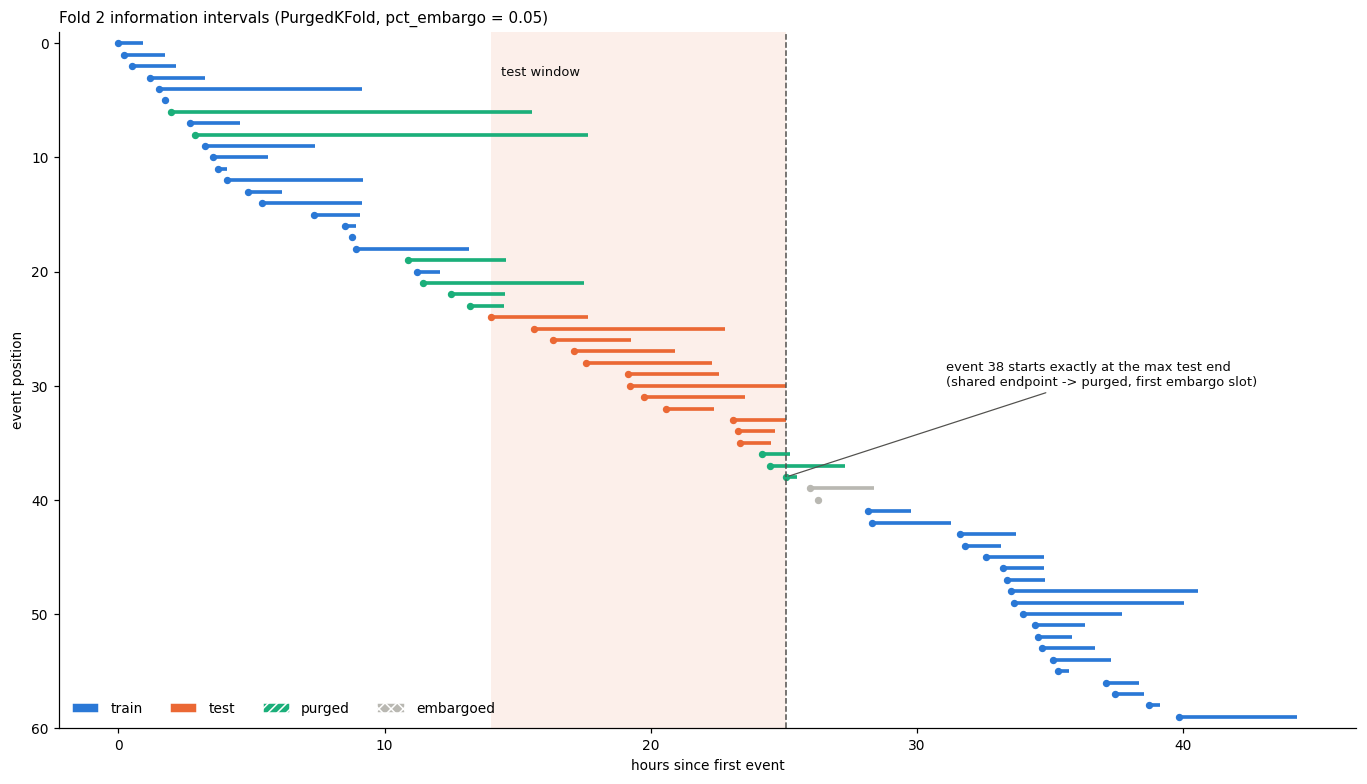

In [8]:
def plot_timeline(ax, d, title):
    cm = category_matrix([d])[0]
    t0 = info.index[0]
    hrs = lambda t: (t - t0) / pd.Timedelta("1h")
    for i in range(N):
        c = COLORS[CATS[cm[i]]]
        ax.plot([hrs(info.index[i]), hrs(info.iloc[i])], [i, i], color=c, lw=2.4, solid_capstyle="butt")
        ax.plot(hrs(info.index[i]), i, "o", color=c, ms=3.8)
    ax.axvspan(hrs(d.test_start), hrs(d.test_end), color=COLORS["test"], alpha=0.10, lw=0)
    ax.axvline(hrs(d.test_end), color="#52514e", lw=1, ls="--")
    ax.set_ylim(N, -1); ax.set_xlabel("hours since first event"); ax.set_ylabel("event position")
    ax.set_title(title, loc="left", fontsize=10)
    return hrs

fig, ax = plt.subplots(figsize=(12.5, 7.2))
hrs = plot_timeline(ax, details_e[2], "Fold 2 information intervals (PurgedKFold, pct_embargo = 0.05)")
ax.annotate("event 38 starts exactly at the max test end\n(shared endpoint -> purged, first embargo slot)",
            xy=(hrs(info.index[38]), 38), xytext=(hrs(info.index[38]) + 6, 30), fontsize=8.5, color="#0b0b0b",
            arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8))
ax.annotate("test window", xy=(hrs(details_e[2].test_start), 2.5), xytext=(hrs(details_e[2].test_start) + 0.4, 2.5),
            fontsize=8.5, color="#0b0b0b", va="center")
ax.legend(handles=handles, loc="lower left", ncol=4, frameon=False)
fig.tight_layout(); plt.show()

## 6. Per-fold counts and assertions

Everything below is checked, not eyeballed. The *audit* recomputes overlap pairs by brute force and re-derives the
embargo window from the documented rule (`searchsorted(..., side="left")`, `m` positions, clipped) and compares it
with what the library reported.

In [9]:
def check(details, pct, name):
    m = int(np.floor(N * pct))
    kf_tests = [te for _, te in KFold(K, shuffle=False).split(X)]
    seen_as_test = np.zeros(N, dtype=int)
    for f, d in enumerate(details):
        parts = [d.train, d.test, d.purged, d.embargoed]
        allpos = np.concatenate(parts)
        assert len(allpos) == N and len(set(allpos)) == N, "categories must partition the sample"
        assert np.array_equal(d.test, kf_tests[f]), "test folds must equal KFold(shuffle=False)"
        assert not set(d.train) & set(d.test)
        seen_as_test[d.test] += 1
        # 1) zero remaining train/test interval overlaps
        assert not overlap_matrix(d.train, d.test).any(), f"{name} fold {f}: leakage left"
        # 2) purged = exactly the non-test events that overlap some test event (independent brute force)
        others = np.setdiff1d(np.arange(N), d.test)
        expected_purged = others[overlap_matrix(others, d.test).any(1)]
        assert np.array_equal(d.purged, expected_purged), f"{name} fold {f}: wrong purge set"
        # 3) window uses the MAXIMUM end of the fold, not the last row's end
        assert d.test_end == info.iloc[d.test].max() and d.test_start == info.index[d.test[0]]
        # 4) embargo: documented window, clipped at the end; purge applied independently on top of it
        p = int(np.searchsorted(info.index, d.test_end, side="left"))
        window = set(range(p, min(p + m, N)))
        assert set(d.embargoed) == window - set(d.test) - set(d.purged), f"{name} fold {f}: wrong embargo set"
        assert window - set(d.test) <= set(d.purged) | set(d.embargoed), "embargo window must be excluded from train"
        assert not window & set(d.train)
    assert (seen_as_test == 1).all(), "every observation must be in exactly one test fold"

check(details0, 0.0, "embargo=0")
check(details_e, PCT, f"embargo={PCT}")
# determinism: a second pass is bit-identical
again = list(cv_e.split(X))
assert all(np.array_equal(a, d.train) and np.array_equal(b, d.test) for (a, b), d in zip(again, details_e))

# planted boundary cases
assert 11 in details0[1].purged                                        # train event ending exactly at the test start
assert 8 in details0[1].purged                                         # long event containing the test window
assert info.index[38] == details_e[2].test_end and 38 in details_e[2].purged      # starts exactly at max test end
assert details_e[2].embargoed.tolist() == [39, 40]                     # p = 38 is already purged -> m-1 more
assert 38 in details0[2].purged and 39 in details0[2].train            # without embargo 39 stays in train
assert 5 not in details0[0].purged                                     # zero-duration events do not break anything
print("all structural assertions passed")

summary = pd.concat({
    "KFold": kfold_audit[["n_test", "n_train", "leaking_train_events"]],
    "Purged, m=0": fold_table(details0)[["n_train", "n_purged", "n_embargoed"]].assign(
        leaking_train_events=[int(overlap_matrix(d.train, d.test).any(1).sum()) for d in details0]),
    f"Purged, m={M}": fold_table(details_e)[["n_train", "n_purged", "n_embargoed"]].assign(
        leaking_train_events=[int(overlap_matrix(d.train, d.test).any(1).sum()) for d in details_e]),
}, axis=1)
summary

all structural assertions passed


KFold                              Purged, m=0                                           Purged, m=3                       \
     n_test n_train leaking_train_events     n_train n_purged n_embargoed leaking_train_events     n_train n_purged n_embargoed   
fold                                                                                                                              
0        12      48                   17          31       17           0                    0          28       17           3   
1        12      48                   11          37       11           0                    0          34       11           3   
2        12      48                    9          39        9           0                    0          37        9           2   
3        12      48                   10          38       10           0                    0          35       10           3   
4        12      48                    4          44        4           0                    0          44        4           0   

                           
     leaking_train_events  
fold                       
0                       0  
1                       0  
2                       0  
3                       0  
4                       0

## 7. A minimal scikit-learn `Pipeline`: preprocessing is fitted inside each fold

The splitter is passed as `cv=`. `cross_validate` clones the whole pipeline per fold and fits the `StandardScaler` on
that fold's **training rows only**. The check below compares each fitted scaler mean with the mean of exactly those rows
(and shows it differs from the full-sample mean the scaler would see if it were fitted outside the loop).
Labels are noise, so accuracy is expected near 0.5 — this section is about *where the fit happens*, not about performance.

In [10]:
pipe = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
res = cross_validate(pipe, X, y, cv=cv_e, scoring="accuracy", return_estimator=True)

rows = []
for f, (est, d) in enumerate(zip(res["estimator"], details_e)):
    scaler = est.named_steps["scale"]
    train_mean = X.iloc[d.train]["momentum"].mean()
    assert np.allclose(scaler.mean_, X.iloc[d.train].mean().to_numpy())            # fitted on this fold's train rows
    assert scaler.n_samples_seen_ == len(d.train)
    assert not np.allclose(scaler.mean_, X.mean().to_numpy())                      # not on the whole sample
    rows.append({"fold": f, "accuracy": res["test_score"][f], "n_train": len(d.train),
                 "scaler_mean(momentum)": scaler.mean_[0], "train_rows_mean": train_mean,
                 "test_rows_mean": X.iloc[d.test]["momentum"].mean(), "full_sample_mean": X["momentum"].mean()})
pd.DataFrame(rows).set_index("fold").round(3)

,accuracy,n_train,scaler_mean(momentum),train_rows_mean,test_rows_mean,full_sample_mean
fold,,,,,,
0,0.750,28,2.552,2.552,0.225,1.538
1,0.667,34,2.205,2.205,0.873,1.538
2,0.333,37,1.537,1.537,1.326,1.538
3,0.667,35,0.869,0.869,2.400,1.538
4,0.500,44,1.083,1.083,2.867,1.538


## 8. What this does *not* do

* **Not walk-forward.** Training sets contain events *after* the test fold as well as before it (that is the point of
  K-Fold with purging). It estimates how a model generalises across the sample, not how a live model trained only on the
  past would have behaved. A walk-forward / anchored scheme (and CPCV) is a separate tool, not implemented here.
* **Purging and embargo do not license test-data peeking.** They only remove *label-overlap* leakage between a fold's
  train and test events. Feature selection, scaling, hyper-parameter tuning or threshold choice that look at the
  test fold (or at the whole sample) still contaminate the estimate. Any tuning needs its own nested validation inside the
  training part.
* **A subset needs a new splitter.** `PurgedKFold` is bound to the exact events it was built from. For a training
  window or the inner loop of nested validation, build a fresh `PurgedKFold` from `samples_info_sets.loc[subset.index]`
  (the embargo then refers to the subset size).
* Single asset only, chronological and unique timestamps; `groups`, `MultiIndex`, unsorted or duplicated inputs are rejected.
  Sample weights, scoring and model fitting stay with the caller. The synthetic data have no edge by construction.

The cell above this one already asserted everything this notebook claims.

In [11]:
print("PurgedKFold demonstration complete: all assertions passed.")

PurgedKFold demonstration complete: all assertions passed.
